# Exploratory Data Analysis (EDA) for Scraped News Data
### LimeoX AI/ML Foundation Training — Practical Lecture Notebook

**Goal:** Understand distributions, patterns, relationships, source behavior, content quality, and time-based trends before feature engineering or machine learning.

Designed for news data with fields such as `news_url_clean`, `title_clean`, `content_clean`, `published_at_utc`, `scraped_at_utc`, `author_clean`, `domain`, and optional `article_niche`/`category`.

**EDA principle:** describe and investigate the data; do not silently modify or delete records. Cleaning and validation belong in earlier pipeline stages.

## Learning outcomes

Students will learn to:
1. Profile dataset shape, schema, data types, missingness, uniqueness, and duplicates.
2. Analyze title/content lengths and source/category distributions.
3. Explore publication-time patterns and scrape delay.
4. Compare groups and inspect relationships between variables.
5. Identify suspicious extraction patterns without automatically deleting records.
6. Visualize findings and write evidence-based recommendations.

**Workflow:** Load → Profile → Univariate analysis → Grouped analysis → Time analysis → Relationships → Anomaly investigation → Findings.

## 1. Setup
Install dependencies if needed: `pip install pandas numpy matplotlib`.

In [1]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)
warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_SEED = 42
OUTPUT_DIR = Path("eda_output")
OUTPUT_DIR.mkdir(exist_ok=True)
print("Pandas:", pd.__version__, "| NumPy:", np.__version__)

Pandas: 3.0.3 | NumPy: 2.4.6


## 2. Load data

The loader checks likely outputs from the previous preprocessing/validation notebooks. If no CSV is found, it generates synthetic demonstration data so the notebook can run end-to-end. Synthetic data is for practice only, not real business conclusions.

In [2]:
CANDIDATE_PATHS = [
    Path("news_validation_all_categorized.csv"),
]
DATA_PATH = next((p for p in CANDIDATE_PATHS if p.exists()), None)

if DATA_PATH is not None:
    df = pd.read_csv(DATA_PATH, low_memory=False)
    print("Loaded:", DATA_PATH.resolve())
else:
    print("No candidate CSV found — using synthetic demonstration data.")
    rng = np.random.default_rng(RANDOM_SEED)
    domains = ["example-finance.com", "daily-market.test", "global-news.test", "tech-wire.test"]
    authors = ["A. Khan", "S. Ahmed", "Staff Writer", None, "Editorial Desk"]
    niches = ["Markets", "Technology", "Business", "World"]
    n = 240
    published = pd.to_datetime("2026-08-01", utc=True) + pd.to_timedelta(rng.integers(0, 60*24*60, size=n), unit="m")
    title_templates = [
        "Company reports quarterly earnings amid market uncertainty",
        "Technology shares rise as investors assess new forecasts",
        "Oil prices move after latest economic data release",
        "Analysts discuss outlook for global financial markets",
        "New policy announcement affects business confidence",
        "Major technology firm introduces a new product",
        "Stocks fall as traders react to central bank comments",
        "Retail sales data signals a shift in consumer demand",
    ]
    titles = [title_templates[i % len(title_templates)] for i in rng.permutation(n)]
    contents = []
    for i in range(n):
        length = int(max(80, rng.lognormal(mean=6.0, sigma=0.65)))
        contents.append(("Synthetic article text for EDA practice. " * (length // 40 + 2))[:length])
    df = pd.DataFrame({
        "news_url_clean": [f"https://{domains[i % len(domains)]}/article/{i}" for i in range(n)],
        "title_clean": titles,
        "content_clean": contents,
        "published_at_utc": published.astype(str),
        "scraped_at_utc": (published + pd.to_timedelta(rng.integers(5, 180, size=n), unit="m")).astype(str),
        "author_clean": [authors[i % len(authors)] for i in range(n)],
        "domain": [domains[i % len(domains)] for i in range(n)],
        "article_niche": [niches[i % len(niches)] for i in range(n)],
    })

print("Dataset shape:", df.shape)
display(df.head())

Loaded: D:\limeox\pre internship\6th data labeling and eda\news_validation_all_categorized.csv
Dataset shape: (77430, 12)


,source_row_index,title_clean,news_url_clean,published_at_utc,author_clean,content_clean,domain,published_at_utc_parsed,validation_issue_count,validation_issue_codes,validation_disposition,category
0,0,Five counties remain under Orange warning for Storm Boelo,https://www.rte.ie/news/ireland/2026/1025/1596760-storm-boelo-ireland,2026-10-24 23:01:00+00:00,RTÉ News,"Storm Boelo has brought severe wind and rain to the south, southwest and north of Ireland with Status Orange weather...",rte.ie,2026-10-24 23:01:00+00:00,0,NaN,ACCEPT,Science/Environment
1,1,Man's body found at Dublin waste recycling facility,https://www.rte.ie/news/dublin/2026/1024/1596714-body-dublin,2026-10-24 10:29:11+00:00,Colman O'Sullivan,An investigation is under way after the body of a man was found at a waste recycling facility in west Dublin. The ma...,rte.ie,2026-10-24 10:29:11+00:00,0,NaN,ACCEPT,Crime/Justice
2,2,Three people arrested over Waterford attack released,https://www.rte.ie/news/munster/2026/1024/1596710-waterford-investigation,2026-10-24 09:33:00+00:00,Marc O'Driscoll,Three people who were arrested in connection with an arson attack that resulted in the deaths of four people in Wate...,rte.ie,2026-10-24 09:33:00+00:00,0,NaN,ACCEPT,Crime/Justice
3,3,"Over 22,000 taking part in 45th Dublin Marathon",https://www.rte.ie/news/ireland/2026/1025/1596750-dublin-marathon,2026-10-24 23:05:20+00:00,Maggie Doyle,"The 45th Irish Life Dublin Marathon is taking place today, with thousands of runners taking part and many thousands ...",rte.ie,2026-10-24 23:05:20+00:00,0,NaN,ACCEPT,Sports
4,4,Blue Planet III is keeping the rough edges in the age of AI,https://www.theverge.com/ai-artificial-intelligence/1018205/blue-planet-iii-authentic-organic-ai,2026-10-24 21:29:12+00:00,Terrence O'Brien,BBC's Blue Planet III is keeping in shots that would normally end up on the cutting room floor to prove it's real. B...,theverge.com,2026-10-24 21:29:12+00:00,0,NaN,ACCEPT,Technology


## 3. Map common field names

The mapping allows the notebook to work with several common column naming conventions without overwriting the source columns.

In [3]:
def first_existing(columns, candidates):
    return next((name for name in candidates if name in columns), None)

COLS = {
    "url": first_existing(df.columns, ["news_url_clean", "url", "news_url", "shared_url"]),
    "title": first_existing(df.columns, ["title_clean", "title", "headline"]),
    "content": first_existing(df.columns, ["content_clean", "content", "article_text", "text", "body"]),
    "published": first_existing(df.columns, ["published_at_utc", "published_at", "published_date", "publication_time"]),
    "scraped": first_existing(df.columns, ["scraped_at_utc", "scraped_at", "scrape_time", "scraped_datetime"]),
    "author": first_existing(df.columns, ["author_clean", "author", "byline"]),
    "domain": first_existing(df.columns, ["domain", "source_domain", "website"]),
    "category": first_existing(df.columns, ["article_niche", "category", "topic", "section"]),
}
print(COLS)

{'url': 'news_url_clean', 'title': 'title_clean', 'content': 'content_clean', 'published': 'published_at_utc', 'scraped': None, 'author': 'author_clean', 'domain': 'domain', 'category': 'category'}


## 4. Dataset overview and schema
Check shape, data types, missingness, uniqueness, exact duplicate rows, and memory use.

In [4]:
overview = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "missing": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "unique_non_null": df.nunique(dropna=True),
})
display(overview.sort_values("missing_pct", ascending=False))
print(f"Rows: {len(df):,} | Columns: {df.shape[1]:,}")
print("Duplicate column names:", df.columns[df.columns.duplicated()].tolist())
print("Exact duplicate rows:", int(df.duplicated().sum()))
print("Memory usage (MB):", round(df.memory_usage(deep=True).sum() / 1024**2, 2))

,dtype,non_null,missing,missing_pct,unique_non_null
validation_issue_codes,float64,0,77430,100.00,0
published_at_utc,str,70152,7278,9.40,61041
published_at_utc_parsed,str,70152,7278,9.40,61041
author_clean,str,73929,3501,4.52,15812
news_url_clean,str,77430,0,0.00,77430
title_clean,str,77430,0,0.00,75072
source_row_index,int64,77430,0,0.00,77430
content_clean,str,77430,0,0.00,77430
domain,str,77430,0,0.00,48
validation_issue_count,int64,77430,0,0.00,1


Rows: 77,430 | Columns: 12
Duplicate column names: []
Exact duplicate rows: 0
Memory usage (MB): 435.54


## 5. Missingness and completeness
Missing values may be informative: author or publication time may be absent more often for particular sources. Missing does not automatically mean invalid.

,missing,missing_pct
validation_issue_codes,77430,100.00
published_at_utc,7278,9.40
published_at_utc_parsed,7278,9.40
author_clean,3501,4.52
news_url_clean,0,0.00
title_clean,0,0.00
source_row_index,0,0.00
content_clean,0,0.00
domain,0,0.00
validation_issue_count,0,0.00


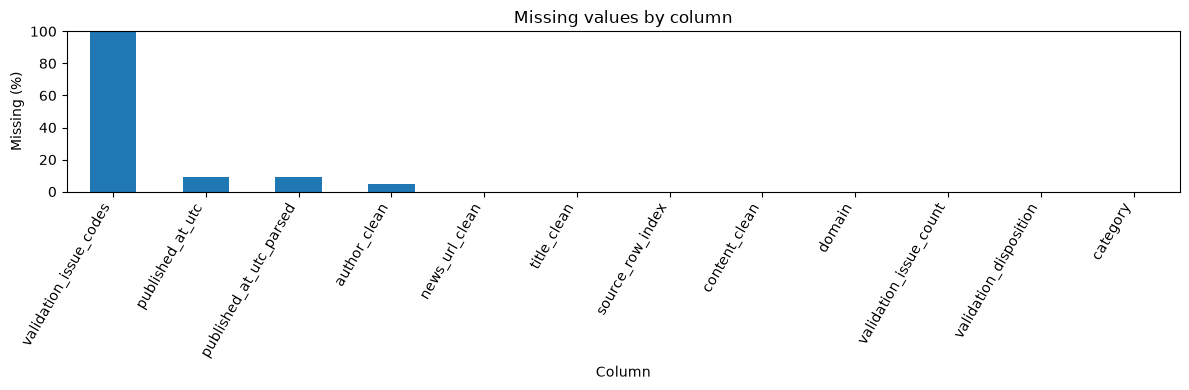

In [5]:
missing_summary = overview[["missing", "missing_pct"]].sort_values("missing_pct", ascending=False)
display(missing_summary)
ax = missing_summary["missing_pct"].plot(kind="bar", figsize=(12, 4))
ax.set_title("Missing values by column")
ax.set_ylabel("Missing (%)")
ax.set_xlabel("Column")
ax.set_ylim(0, 100)
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

In [6]:
if COLS["domain"]:
    tmp = df.copy()
    tmp["_domain_for_group"] = tmp[COLS["domain"]].fillna("(missing domain)")
    records = []
    for domain, group in tmp.groupby("_domain_for_group", dropna=False):
        row = {"domain": domain, "articles": len(group)}
        if COLS["author"]:
            row["author_missing_pct"] = group[COLS["author"]].isna().mean() * 100
        if COLS["published"]:
            row["published_missing_pct"] = group[COLS["published"]].isna().mean() * 100
        records.append(row)
    display(pd.DataFrame(records).sort_values("articles", ascending=False).round(2))
else:
    print("No domain/source field detected.")

,domain,articles,author_missing_pct,published_missing_pct
3,cbsnews.com,2500,9.96,0.00
18,khaleejtimes.com,2500,0.00,0.00
43,thenationalnews.com,2500,0.00,8.60
22,middleeasteye.net,2499,0.24,0.24
23,mirror.co.uk,2498,0.00,0.00
0,al-monitor.com,2498,0.00,0.00
4,chicagotribune.com,2498,0.00,0.00
12,gulfnews.com,2498,0.28,99.96
45,theverge.com,2498,0.00,0.00
34,salon.com,2498,0.00,0.00


## 6. Uniqueness and duplicate patterns

For news data, exact row duplicates, duplicate URLs, repeated titles, and repeated bodies are different signals. Treat them as **candidates to investigate**, not automatic deletion instructions.

In [7]:
duplicate_stats = {
    "exact_duplicate_rows": int(df.duplicated().sum()),
    "duplicate_url_rows": int(df[COLS["url"]].duplicated(keep=False).sum()) if COLS["url"] else None,
    "duplicate_title_rows": int(df[COLS["title"]].astype("string").str.strip().duplicated(keep=False).sum()) if COLS["title"] else None,
    "duplicate_content_rows": int(df[COLS["content"]].astype("string").str.strip().duplicated(keep=False).sum()) if COLS["content"] else None,
}
display(pd.Series(duplicate_stats, name="row_count").to_frame())

,row_count
exact_duplicate_rows,0
duplicate_url_rows,0
duplicate_title_rows,3063
duplicate_content_rows,0


In [8]:
if COLS["url"]:
    display(df[df[COLS["url"]].duplicated(keep=False)].sort_values(COLS["url"]).head(20))
if COLS["title"]:
    title_dupes = df[df[COLS["title"]].astype("string").str.strip().duplicated(keep=False)]
    cols = [c for c in [COLS["domain"], COLS["published"], COLS["title"], COLS["url"]] if c]
    display(title_dupes[cols].sort_values(COLS["title"]).head(20))

,source_row_index,title_clean,news_url_clean,published_at_utc,author_clean,content_clean,domain,published_at_utc_parsed,validation_issue_count,validation_issue_codes,validation_disposition,category


,domain,published_at_utc,title_clean,news_url_clean
966,standard.co.uk,2026-10-23 16:12:17+00:00,"'Andy is getting it done', says Trump as he claims UK 'opening up North Sea oil'",https://www.standard.co.uk/news/environment/donald-trump-andy-burnham-uk-government-north-sea-prime-minister-b130213...
1728,independent.co.uk,2026-10-23 16:12:17+00:00,"'Andy is getting it done', says Trump as he claims UK 'opening up North Sea oil'",https://www.independent.co.uk/news/business/donald-trump-andy-burnham-uk-government-north-sea-prime-minister-b307238...
47636,seattletimes.com,2026-10-05 22:06:06+00:00,"'Days of Our Lives,' 'General Hospital' star Robert Kelker-Kelly dies at 62",https://www.seattletimes.com/entertainment/days-of-our-lives-general-hospital-star-robert-kelker-kelly-dies-at-62
48013,denverpost.com,2026-10-05 20:32:16+00:00,"'Days of Our Lives,' 'General Hospital' star Robert Kelker-Kelly dies at 62",https://www.denverpost.com/2026/10/05/robert-kelker-kelly-dead-days-of-our-lives
75,standard.co.uk,2026-10-24 20:56:21+00:00,'It's about principle',https://www.standard.co.uk/news/uk/dup-stormont-bbc-belfast-bbc-radio-b1302185.html
329,independent.co.uk,2026-10-24 20:56:21+00:00,'It's about principle',https://www.independent.co.uk/news/uk/home-news/gavin-robinson-dup-sammy-wilson-minister-orange-order-b3072671.html
2145,standard.co.uk,2026-10-22 11:08:55+00:00,'Limited' Government services temporarily offline amid PHP cybersecurity issue,https://www.standard.co.uk/news/tech/government-downing-street-work-press-association-b1301916.html
13095,independent.co.uk,2026-10-22 11:08:55+00:00,'Limited' Government services temporarily offline amid PHP cybersecurity issue,https://www.independent.co.uk/news/uk/politics/government-downing-street-work-openai-b3071412.html
6833,npr.org,2026-10-07 00:00:00+00:00,'Medicare for All' message attracts midterm voters buckling under medical bills,https://www.npr.org/2026/10/07/nx-s1-5992772/medicare-for-all-midterm-voters-medical-bills-affordability
6925,npr.org,2026-10-06 00:00:00+00:00,'Medicare for All' message attracts midterm voters buckling under medical bills,https://www.npr.org/2026/10/06/nx-s1-5989436/medicare-for-all-message-attracts-midterm-voters-buckling-under-medical...


## 7. Text-length distributions

Article length is both a content characteristic and an extraction diagnostic. Very short text may indicate failed extraction or a genuinely brief item; very long text may contain navigation, comments, or concatenated pages.

In [9]:
if COLS["title"]:
    df["_title_chars"] = df[COLS["title"]].astype("string").str.len()
    df["_title_words"] = df[COLS["title"]].astype("string").str.split().str.len()
if COLS["content"]:
    df["_content_chars"] = df[COLS["content"]].astype("string").str.len()
    df["_content_words"] = df[COLS["content"]].astype("string").str.split().str.len()

length_cols = [c for c in ["_title_chars", "_title_words", "_content_chars", "_content_words"] if c in df.columns]
display(df[length_cols].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
_title_chars,77430.0,66.801382,22.777579,8.0,9.0,26.0,53.0,69.0,81.0,100.0,117.0,203.0
_title_words,77430.0,10.836911,3.807866,1.0,2.0,4.0,8.0,11.0,13.0,17.0,20.0,38.0
_content_chars,77430.0,5426.712282,7091.238305,718.0,969.0,1233.0,2249.0,3690.0,6205.0,13850.65,35482.49,281142.0
_content_words,77430.0,893.909609,1174.833237,133.0,161.0,201.0,369.0,609.0,1018.0,2277.55,5912.0,48395.0


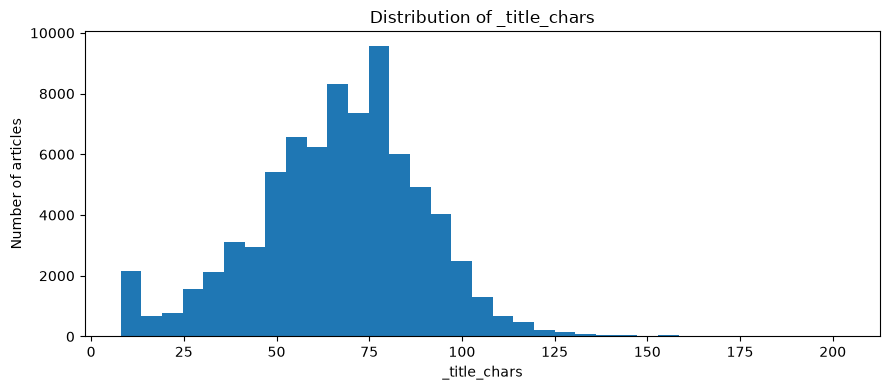

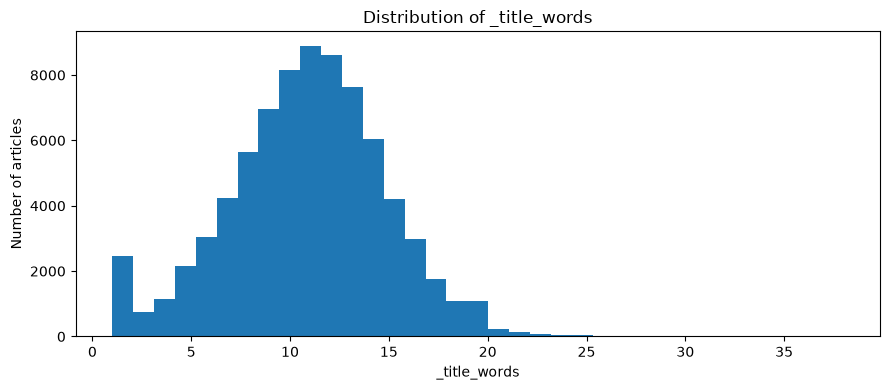

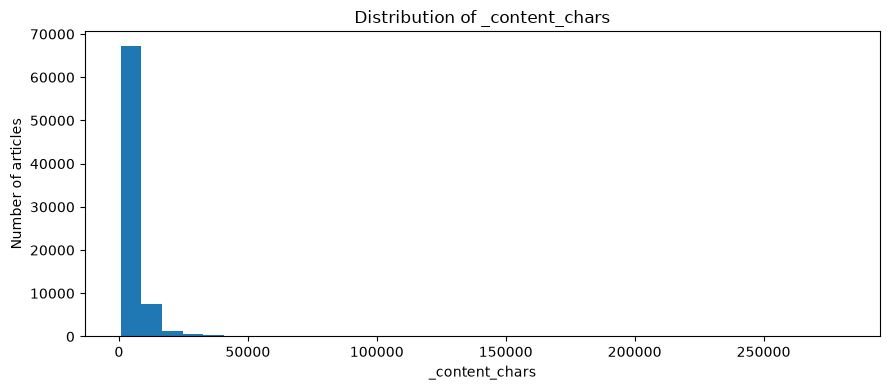

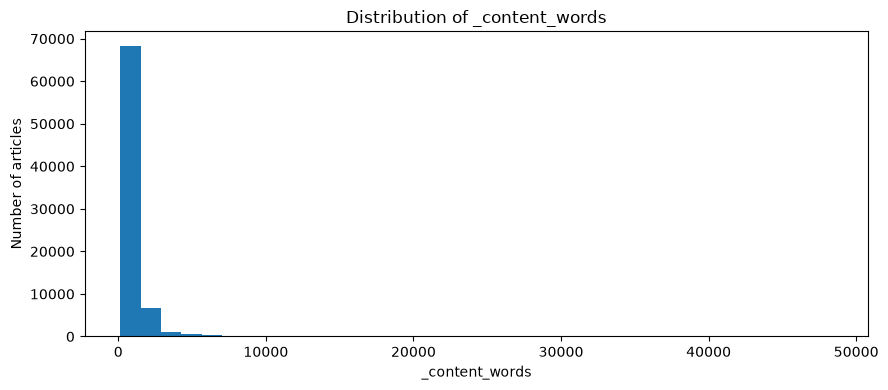

In [10]:
for col in length_cols:
    values = pd.to_numeric(df[col], errors="coerce").dropna()
    if len(values):
        plt.figure(figsize=(9, 4))
        plt.hist(values, bins=35)
        plt.title(f"Distribution of {col}")
        plt.xlabel(col)
        plt.ylabel("Number of articles")
        plt.tight_layout()
        plt.show()

In [12]:
if "_content_words" in df.columns:
    display(df.nsmallest(10, "_content_words")[[c for c in [COLS["domain"], COLS["title"], COLS["published"], "_content_words", COLS["url"]] if c]])
    display(df.nlargest(10, "_content_words")[[c for c in [COLS["domain"], COLS["title"], COLS["published"], "_content_words", COLS["url"]] if c]])

,domain,title_clean,published_at_utc,_content_words,news_url_clean
8216,standard.co.uk,UK ticket-holder wins huge £111million EuroMillions jackpot,2026-09-26 07:57:31+00:00,133,https://www.standard.co.uk/news/uk/national-lottery-euromillions-jackpot-winner-uk-b1298462.html
4903,theverge.com,The Pixel Watch 5 is a better value at $65 off,2026-10-06 14:00:00+00:00,147,https://www.theverge.com/gadgets/1003583/pixel-watch-5-prime-day-deal-sale
4574,standard.co.uk,Health And Beauty,NaN,150,https://www.standard.co.uk/esrewards/healthandbeauty
5207,npr.org,Author Tommy Orange confronts the phenomenon of 'pretendians' : Here & Now Anytime,2026-10-12 00:00:00+00:00,150,https://www.npr.org/2026/10/12/nx-s1-5998883/author-tommy-orange-confronts-the-phenomenon-of-pretendians
5686,cbsnews.com,"Motorcyclist spotted going 120 mph leads deputies on multi-county chase, runs out of gas, authorities say",2026-10-15 01:23:24+00:00,150,https://www.cbsnews.com/texas/news/johnson-county-motorcycle-chase-runs-out-of-gas-october-2026
7244,rte.ie,Sixties Icon & Dettori take St Leger at York,2006-09-09 06:00:00+00:00,150,https://www.rte.ie/sport/racing/2006/0909/208914-york
8921,theverge.com,"CNN reports the US military nearly intercepted a Chinese ship based on an ""entirely false"" AI-generated report.",2026-09-18 22:57:37+00:00,150,https://www.theverge.com/ai-artificial-intelligence/997724/us-military-ai-intel-report-chinese-ship
9413,bbc.com,BBC Audio,NaN,150,https://www.bbc.com/audio/play/p0ln90sh
10761,npr.org,U.S. troops are leaving Iraq. What does that mean for U.S. influence in the region? : Consider This from NPR,2026-09-27 00:00:00+00:00,150,https://www.npr.org/2026/09/27/nx-s1-5982794/u-s-troops-are-leaving-iraq-what-does-that-mean-for-u-s-influence-in-th...
11759,cbsnews.com,Calling all heroes: Nominate a hometown hero for American Red Cross Los Angeles Region 2027 awards luncheon,2026-10-13 21:39:12+00:00,150,https://www.cbsnews.com/losangeles/news/american-red-cross-los-angeles-region-2027-hometown-heroes


,domain,title_clean,published_at_utc,_content_words,news_url_clean
59236,foxnews.com,"Johnny Depp wins defamation trial against Amber Heard, awarded over $10m in damages",2022-09-02 14:08:04+00:00,48395,https://www.foxnews.com/live-news/johnny-depp-amber-heard-defamation-trial-court-case
36557,theintercept.com,The Intercept,NaN,42208,https://theintercept.com/feeds
60293,foxnews.com,"13 US service members killed in Kabul airport explosion, officials say: LIVE UPDATES",2021-08-31 02:14:15+00:00,42194,https://www.foxnews.com/live-news/live-updates-taliban-gain-more-ground-in-afghanistan-as-they-close-in-on-kabul
43513,seattletimes.com,Voter guide 2026: What's at stake in WA general election,2026-10-15 13:00:00+00:00,36718,https://www.seattletimes.com/seattle-news/politics/seattle-times-voter-guide-for-wa-general-election-2026
58128,foxnews.com,Antisemitism on campus surges as agitators take over,2024-04-28 07:08:39+00:00,36444,https://www.foxnews.com/live-news/antisemitism-campus-surges-agitators-take-over-columbia-yale-universities
59325,foxnews.com,"Russia says it won't use nuclear weapons in Ukraine, despite threatening rhetoric",2022-05-06 13:30:56+00:00,35861,https://www.foxnews.com/live-news/russia-ukraine-war-news-putin-zelenskyy-live
57813,foxnews.com,Trump arrives at Republican National Convention night 2 with focus on 'Make America Safe Once Again',2024-07-17 06:01:28+00:00,30746,https://www.foxnews.com/live-news/rnc-2024-republican-national-convention-donald-trump
34310,propublica.org,A Hospital Helped a Beloved Doctor's Practice Flourish Even as It Suspected He Was Hurting Patients,2024-12-07 10:00:00+00:00,30356,https://www.propublica.org/article/thomas-weiner-montana-st-peters-hospital-oncology
36742,propublica.org,El caso Cienfuegos: el conflicto que hundió la lucha contra las drogas de México y Estados Unidos,2022-12-12 18:00:00+00:00,28383,https://www.propublica.org/article/mexico-carteles-drogas-cienfuegos-caso-dea
34867,propublica.org,They Tried to Expose Louisiana Judges Who Had Systematically Ignored Prisoners' Petitions. No One Listened.,2023-11-04 09:00:00+00:00,24803,https://www.propublica.org/article/louisiana-judges-ignored-prisoners-petitions-without-review-fifth-circuit


## 8. Source/domain distribution
Inspect which domains contribute most, whether the data is concentrated in a few sites, and how article lengths vary by source.

,articles
domain,
cbsnews.com,2500
khaleejtimes.com,2500
thenationalnews.com,2500
middleeasteye.net,2499
theverge.com,2498
mirror.co.uk,2498
salon.com,2498
chicagotribune.com,2498
al-monitor.com,2498


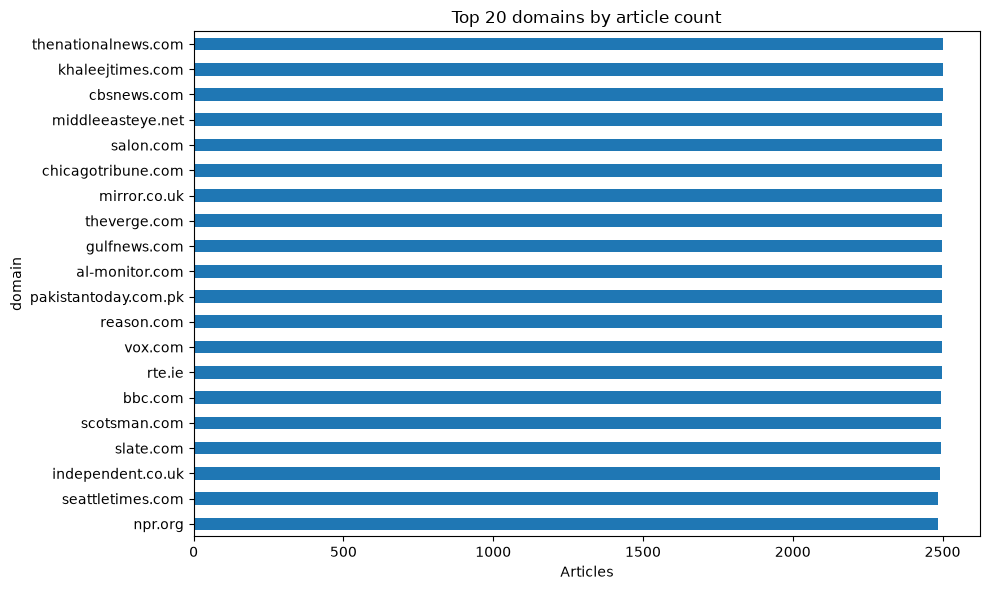

,share_pct
domain,
cbsnews.com,3.23
khaleejtimes.com,3.23
thenationalnews.com,3.23
middleeasteye.net,3.23
theverge.com,3.23
mirror.co.uk,3.23
salon.com,3.23
chicagotribune.com,3.23
al-monitor.com,3.23


In [13]:
if COLS["domain"]:
    source_counts = df[COLS["domain"]].fillna("(missing domain)").value_counts()
    display(source_counts.rename("articles").to_frame().head(30))
    ax = source_counts.head(20).sort_values().plot(kind="barh", figsize=(10, 6))
    ax.set_title("Top 20 domains by article count")
    ax.set_xlabel("Articles")
    plt.tight_layout()
    plt.show()
    display((source_counts / source_counts.sum() * 100).rename("share_pct").to_frame().head(20).round(2))
else:
    print("No domain/source field detected.")

In [14]:
if COLS["domain"] and "_content_words" in df.columns:
    source_length = df.groupby(COLS["domain"], dropna=False).agg(
        articles=("_content_words", "size"),
        median_content_words=("_content_words", "median"),
        mean_content_words=("_content_words", "mean"),
        p95_content_words=("_content_words", lambda s: s.quantile(.95)),
    )
    display(source_length.query("articles >= 3").sort_values("articles", ascending=False).round(1).head(30))

,articles,median_content_words,mean_content_words,p95_content_words
domain,,,,
cbsnews.com,2500,375.0,472.1,1066.1
thenationalnews.com,2500,616.0,665.6,1226.0
khaleejtimes.com,2500,464.0,527.3,1053.2
middleeasteye.net,2499,600.0,749.7,1668.8
gulfnews.com,2498,500.0,603.4,1280.3
chicagotribune.com,2498,614.0,673.9,1288.3
al-monitor.com,2498,599.0,624.6,1034.0
mirror.co.uk,2498,555.5,627.2,1159.0
salon.com,2498,636.5,898.2,2483.1


## 9. Category/niche distribution
Class imbalance matters for classification, recommendation, and topic reporting. Inspect category labels before building models.

,articles
category,
World,14757
Politics,14145
Sports,9151
Crime/Justice,6693
Lifestyle,5557
Culture/Entertainment,5366
Other,5315
Technology,4931
Business/Economy,3698


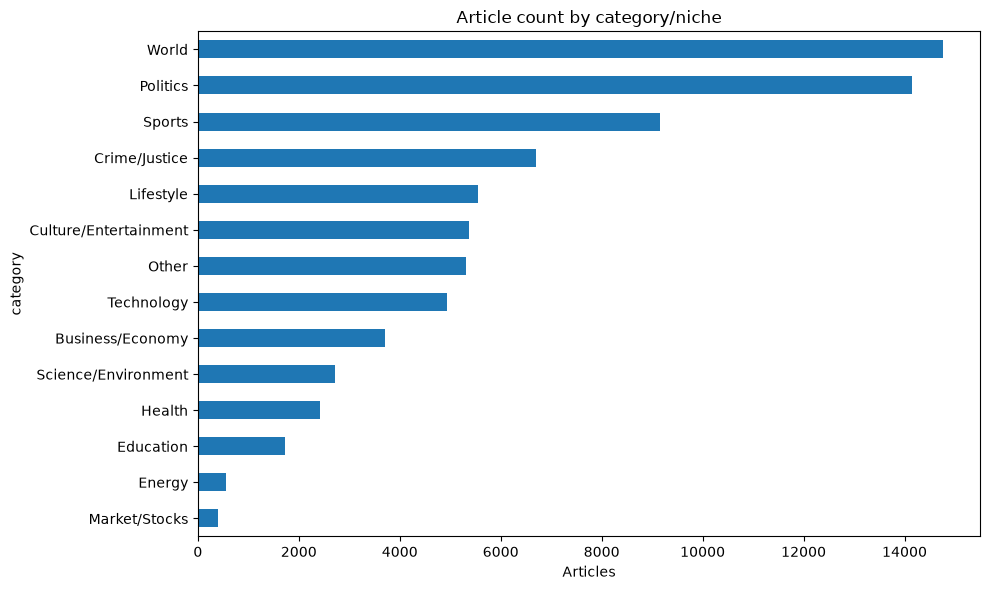

In [15]:
if COLS["category"]:
    category_counts = df[COLS["category"]].fillna("(missing category)").value_counts()
    display(category_counts.rename("articles").to_frame())
    ax = category_counts.head(25).sort_values().plot(kind="barh", figsize=(10, 6))
    ax.set_title("Article count by category/niche")
    ax.set_xlabel("Articles")
    plt.tight_layout()
    plt.show()
else:
    print("No category/niche field detected.")

## 10. Publication-time patterns

Convert timestamps to UTC explicitly. Invalid or missing timestamps become `NaT` and are counted. Explore coverage, articles per day/hour, weekday patterns, and publication-to-scrape delay.

**Caution:** scraper schedules, source timezone conventions, and incomplete history can create apparent trends.

Valid publication timestamps: 62825 / 77430
Earliest: 1999-09-30 04:00:00+00:00 | Latest: 2026-10-30 22:00:48+00:00
Coverage days: 9892.75


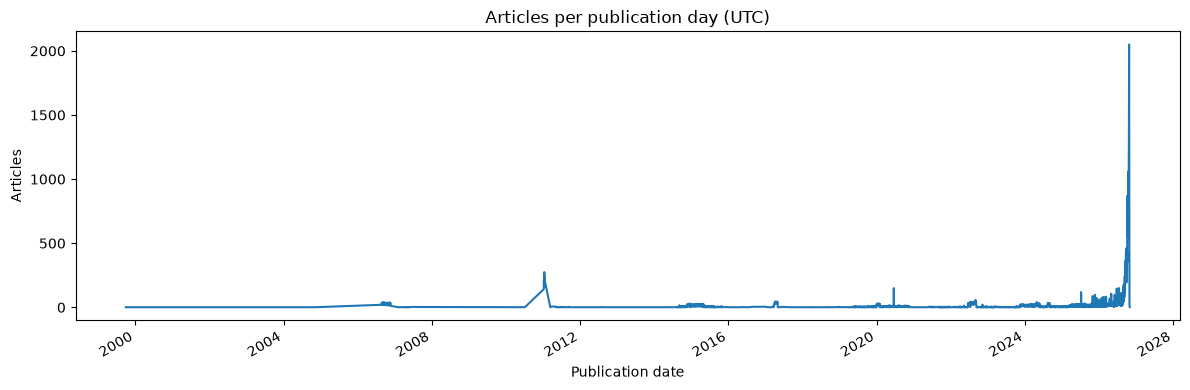

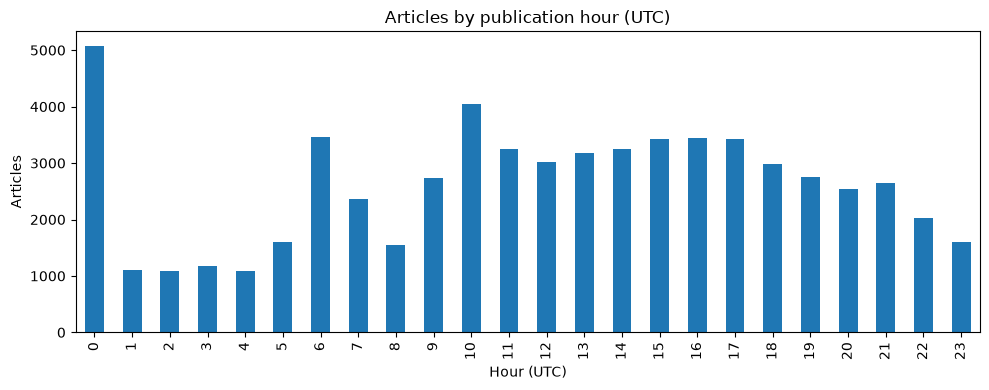

,articles
_published_day_name,
Monday,9307
Tuesday,10047
Wednesday,9952
Thursday,10661
Friday,10069
Saturday,6900
Sunday,5889


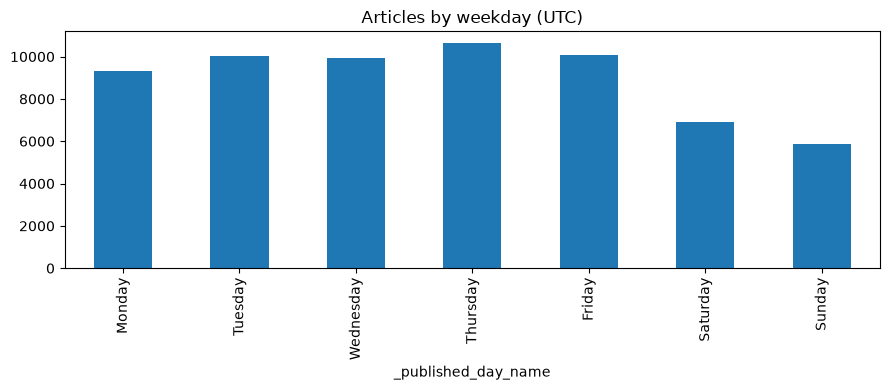

In [16]:
if COLS["published"]:
    df["_published_dt"] = pd.to_datetime(df[COLS["published"]], errors="coerce", utc=True)
    valid_pub = df["_published_dt"].dropna()
    print("Valid publication timestamps:", len(valid_pub), "/", len(df))
    if len(valid_pub):
        print("Earliest:", valid_pub.min(), "| Latest:", valid_pub.max())
        print("Coverage days:", round((valid_pub.max() - valid_pub.min()).total_seconds() / 86400, 2))
        df["_published_date"] = df["_published_dt"].dt.floor("D")
        df["_published_hour_utc"] = df["_published_dt"].dt.hour
        df["_published_day_name"] = df["_published_dt"].dt.day_name()
        daily = df.groupby("_published_date").size()
        ax = daily.plot(figsize=(12, 4))
        ax.set_title("Articles per publication day (UTC)")
        ax.set_xlabel("Publication date")
        ax.set_ylabel("Articles")
        plt.tight_layout()
        plt.show()
        hourly = df["_published_hour_utc"].value_counts().sort_index().reindex(range(24), fill_value=0)
        ax = hourly.plot(kind="bar", figsize=(10, 4))
        ax.set_title("Articles by publication hour (UTC)")
        ax.set_xlabel("Hour (UTC)")
        ax.set_ylabel("Articles")
        plt.tight_layout()
        plt.show()
        order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
        weekdays = df["_published_day_name"].value_counts().reindex(order, fill_value=0)
        display(weekdays.rename("articles").to_frame())
        weekdays.plot(kind="bar", figsize=(9, 4), title="Articles by weekday (UTC)")
        plt.tight_layout()
        plt.show()
else:
    print("No publication timestamp field detected.")

In [17]:
if COLS["published"] and COLS["scraped"]:
    df["_scraped_dt"] = pd.to_datetime(df[COLS["scraped"]], errors="coerce", utc=True)
    df["_publish_to_scrape_minutes"] = (df["_scraped_dt"] - df["_published_dt"]).dt.total_seconds() / 60
    display(df["_publish_to_scrape_minutes"].describe(percentiles=[.01, .05, .5, .95, .99]).to_frame())
    print("Negative publication-to-scrape delays:", int((df["_publish_to_scrape_minutes"] < 0).sum()))
    delay = df["_publish_to_scrape_minutes"].dropna()
    if len(delay):
        clipped = delay.clip(lower=delay.quantile(.01), upper=delay.quantile(.99))
        plt.figure(figsize=(9, 4))
        plt.hist(clipped, bins=40)
        plt.title("Publication-to-scrape delay (clipped to 1st–99th percentile)")
        plt.xlabel("Minutes")
        plt.ylabel("Articles")
        plt.tight_layout()
        plt.show()
else:
    print("Both publication and scrape timestamps are required for scrape-delay analysis.")

Both publication and scrape timestamps are required for scrape-delay analysis.


## 11. Relationships between variables
Compare title length with article length and inspect category mix by domain. Correlation is descriptive, not causal.

Pearson correlation: 0.108
Spearman correlation: 0.164


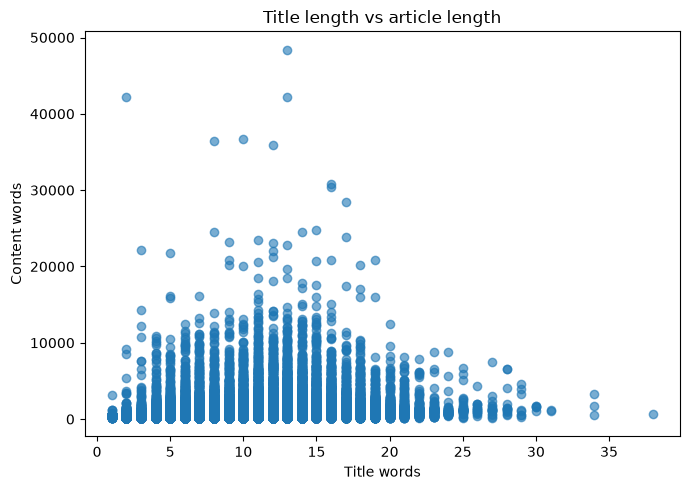

In [18]:
if "_title_words" in df.columns and "_content_words" in df.columns:
    pair = df[["_title_words", "_content_words"]].dropna()
    if len(pair) >= 2:
        print("Pearson correlation:", round(pair.corr(method="pearson").iloc[0, 1], 3))
        print("Spearman correlation:", round(pair.corr(method="spearman").iloc[0, 1], 3))
        plt.figure(figsize=(7, 5))
        plt.scatter(pair["_title_words"], pair["_content_words"], alpha=.6)
        plt.title("Title length vs article length")
        plt.xlabel("Title words")
        plt.ylabel("Content words")
        plt.tight_layout()
        plt.show()

category,Business/Economy,Crime/Justice,Culture/Entertainment,Education,Energy,Health,Lifestyle,Market/Stocks,Other,Politics,Science/Environment,Sports,Technology,World
domain,,,,,,,,,,,,,,
al-monitor.com,1.4,2.3,0.4,0.4,0.8,0.4,0.4,0.0,0.1,3.7,1.5,1.7,0.4,86.5
bbc.com,2.2,7.5,13.5,0.6,0.1,2.3,1.4,0.0,45.6,3.1,3.0,4.7,4.9,11.2
brecorder.com,39.7,5.3,2.0,1.3,4.0,1.3,4.0,4.0,4.6,7.3,2.0,2.0,2.0,20.5
cbsnews.com,3.8,30.3,3.5,4.4,0.8,4.4,5.4,0.0,11.1,12.1,6.5,12.0,2.6,3.0
chicagotribune.com,3.3,6.9,3.7,2.4,0.4,1.6,3.9,0.2,41.2,11.0,1.6,16.3,1.9,5.6
dawn.com,4.5,18.2,1.3,2.6,2.6,7.8,1.9,0.0,14.3,10.4,1.9,9.1,1.3,24.0
denverpost.com,7.6,9.7,4.5,2.7,0.6,2.1,10.9,0.2,10.6,13.6,3.3,28.9,2.2,3.1
deseret.com,6.9,13.5,6.7,3.3,0.6,2.8,4.7,0.3,14.9,10.6,4.3,20.6,1.5,9.1
dw.com,0.1,0.0,0.2,0.0,0.0,0.0,0.0,0.0,9.4,0.4,0.1,0.0,0.6,89.3


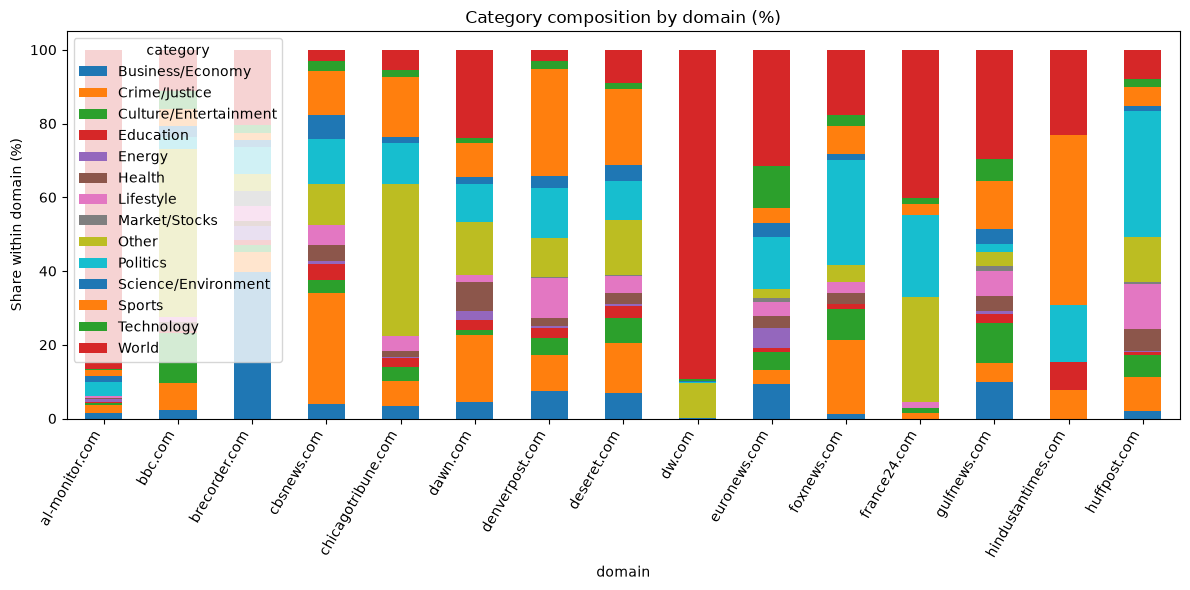

In [19]:
if COLS["domain"] and COLS["category"]:
    mix = pd.crosstab(df[COLS["domain"]], df[COLS["category"]], normalize="index") * 100
    display(mix.round(1).head(25))
    ax = mix.head(15).plot(kind="bar", stacked=True, figsize=(12, 6))
    ax.set_title("Category composition by domain (%)")
    ax.set_ylabel("Share within domain (%)")
    plt.xticks(rotation=60, ha="right")
    plt.tight_layout()
    plt.show()

## 12. Investigate suspicious extraction patterns

The heuristics below flag candidates for manual review. Thresholds are starting points, not universal rules. Do not automatically delete short/long articles.

In [20]:
suspicious = pd.Series(False, index=df.index)
if "_content_words" in df.columns:
    suspicious |= df["_content_words"].fillna(0).lt(40)
    if df["_content_words"].notna().any():
        suspicious |= df["_content_words"].gt(df["_content_words"].quantile(.99))
if COLS["title"]:
    pattern = r"access denied|captcha|robot check|page not found|403 forbidden|enable javascript"
    suspicious |= df[COLS["title"]].astype("string").str.contains(pattern, case=False, na=False)
if "_publish_to_scrape_minutes" in df.columns:
    suspicious |= df["_publish_to_scrape_minutes"].lt(0).fillna(False)

review_cols = [c for c in [COLS["domain"], COLS["title"], COLS["published"], COLS["scraped"], "_title_words", "_content_words", "_publish_to_scrape_minutes", COLS["url"]] if c]
suspicious_records = df.loc[suspicious, review_cols].copy()
print(f"Suspicious candidates: {len(suspicious_records)} / {len(df)} ({len(suspicious_records)/max(len(df), 1):.1%})")
display(suspicious_records.head(50))

KeyError: "['_publish_to_scrape_minutes'] not in index"

## 13. Optional numeric correlation matrix
Use only numeric features; avoid IDs and encoded identifiers.

,_title_chars,_title_words,_content_chars,_content_words,_published_hour_utc,_publish_to_scrape_minutes
_title_chars,1.00,0.11,-0.08,-0.08,-0.04,0.02
_title_words,0.11,1.00,-0.04,-0.04,-0.14,0.06
_content_chars,-0.08,-0.04,1.00,1.00,-0.04,-0.17
_content_words,-0.08,-0.04,1.00,1.00,-0.05,-0.17
_published_hour_utc,-0.04,-0.14,-0.04,-0.05,1.00,0.06
_publish_to_scrape_minutes,0.02,0.06,-0.17,-0.17,0.06,1.00


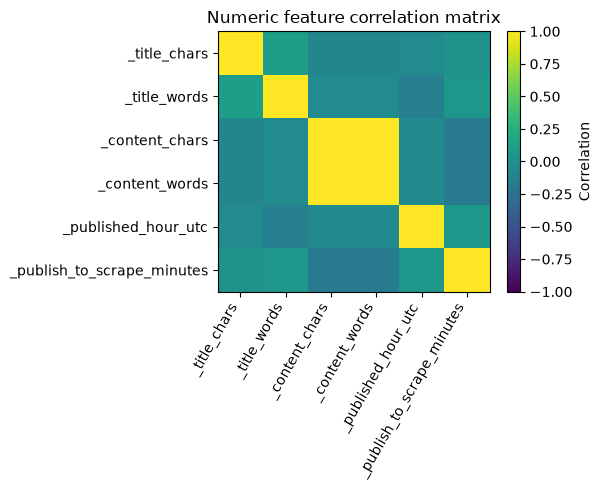

In [ ]:
numeric = df.select_dtypes(include=np.number)
if numeric.shape[1] >= 2:
    corr = numeric.corr(numeric_only=True)
    display(corr.round(2))
    fig, ax = plt.subplots(figsize=(max(6, len(corr.columns)*.8), max(5, len(corr.columns)*.7)))
    image = ax.imshow(corr, aspect="auto", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr.columns)))
    ax.set_xticklabels(corr.columns, rotation=60, ha="right")
    ax.set_yticks(range(len(corr.index)))
    ax.set_yticklabels(corr.index)
    ax.set_title("Numeric feature correlation matrix")
    fig.colorbar(image, ax=ax, label="Correlation")
    plt.tight_layout()
    plt.show()
else:
    print("Fewer than two numeric columns are available.")

## 14. Export EDA outputs
Summaries and candidate records are exported for review. The original source dataset is not overwritten.

In [ ]:
overview.to_csv(OUTPUT_DIR / "column_profile.csv")
missing_summary.to_csv(OUTPUT_DIR / "missingness_summary.csv")
pd.Series(duplicate_stats, name="row_count").to_csv(OUTPUT_DIR / "duplicate_summary.csv")
if "source_counts" in globals():
    source_counts.rename("articles").to_csv(OUTPUT_DIR / "source_distribution.csv")
if "category_counts" in globals():
    category_counts.rename("articles").to_csv(OUTPUT_DIR / "category_distribution.csv")
suspicious_records.to_csv(OUTPUT_DIR / "suspicious_candidates.csv", index=False)
summary = {
    "rows": int(len(df)),
    "columns": int(df.shape[1]),
    "exact_duplicate_rows": int(df.duplicated().sum()),
    "missing_pct_by_column": {str(k): float(v) for k, v in overview["missing_pct"].items()},
    "detected_fields": COLS,
    "outputs_directory": str(OUTPUT_DIR.resolve()),
}
with open(OUTPUT_DIR / "eda_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False)
print("Saved outputs to:", OUTPUT_DIR.resolve())
print(sorted(p.name for p in OUTPUT_DIR.iterdir()))

Saved outputs to: /Users/ummehabiba/Downloads/eda_output
['category_distribution.csv', 'column_profile.csv', 'duplicate_summary.csv', 'eda_summary.json', 'missingness_summary.csv', 'source_distribution.csv', 'suspicious_candidates.csv']


## 15. How to write EDA findings

For each finding, record:
1. **Observation:** What does the chart/table show?
2. **Evidence:** A count, percentage, median, range, or comparison.
3. **Interpretation:** What might explain the pattern?
4. **Caveat:** What else could explain it?
5. **Action:** Investigate, validate, collect more data, or design a feature.

**Illustrative example only:** “One source contributes 38% of rows. This may overrepresent that publisher, although it could reflect genuine publishing volume or the scraper schedule. Compare source coverage over time before deciding whether source balancing is needed.” Do not copy illustrative numbers as your own results.

## 16. Student exercises

1. Find the top three domains and calculate their combined share of articles.
2. Compare median content length across the five largest domains.
3. Compare missing author and publication-time percentages by domain.
4. Plot daily article counts and identify gaps or spikes; suggest two explanations.
5. Investigate repeated titles across different domains: syndication or scraper duplication?
6. Select one suspicious record and document why it deserves review.
7. Write five findings using observation → evidence → interpretation → caveat → action.
8. Explain why automatically deleting every short article or repeated title is unsafe.

## Key takeaways and next lecture

- EDA reveals structure, distributions, missingness, duplicates, source concentration, temporal patterns, and relationships.
- Source and time analyses can expose collection bias and scraper reliability issues.
- Suspicious rows are review candidates, not automatically invalid records.
- Keep EDA separate from data cleaning and log evidence-based findings.

**Recommended next lecture:** Feature Engineering for News/Text Data — converting validated articles into meaningful numerical and categorical signals before embeddings and machine learning.